#### Read image files and prepare input data

In [1]:
import numpy as np 
import cv2
import matplotlib.pyplot as plt

# path to the database - change it if needed
path = 'D:\\Teach_n_Train\\Machine Learning\\code\\yale\\yalefaces_data\\' 

ids = range(1, 16) # 15 people
states = ['centerlight', 'glasses', 'happy', 'leftlight', 
          'noglasses', 'normal', 'rightlight','sad', 
          'sleepy', 'surprised', 'wink' ]
prefix = 'subject'
surfix = '.png' #file extension is png

# open one picture to get the image's size
fn = prefix + '01.' + states[0] + surfix
im = cv2.imread(path + fn, 0)

h = im.shape[0] # hight 
w = im.shape[1] # width

D = h * w
N = len(states)*15 
print(N, D, h, w)

X = np.zeros((D, N))
Y = np.zeros(N)

# collect all data
cnt = 0 

# there are 15 people
for person_id in range(1, 16):
    for state in states:
        
        # get name of each image file
        fn = path + prefix + str(person_id).zfill(2) + '.' + state + surfix
        
        # open the file and read as grey image
        tmp = cv2.imread(fn, cv2.IMREAD_GRAYSCALE)
        
        # then add image to dataset X
        X[:, cnt] = tmp.reshape(D)
        Y[cnt] = states.index(state)
        
        cnt += 1 
Y = Y.astype(int)

165 77760 243 320


#### Doing PCA and Dim. Reduce

In [10]:
# Doing PCA, note that each row is a datapoint
from sklearn.decomposition import PCA

# remain dim. k = 125 - change it! 
pca = PCA(n_components=125) 

# then apply to data X
pca.fit(X.T)

,n_components,125
,copy,True
,whiten,False
,svd_solver,'auto'
,tol,0.0
,iterated_power,'auto'
,n_oversamples,10
,power_iteration_normalizer,'auto'
,random_state,None


#### Build Project Matrix U = (u_1 u_2 ... u_k) : the k first vectors of basis {U}

In [12]:
# then build projection matrix 
U = pca.components_.T
U.shape

(77760, 125)

#### Project X to less-dimention sub-space: $Z = U_k^T . \hat{X}$
#### where $\hat{X} = X - \bar{x}.1^T$

In [14]:
Xhat = np.zeros((D, N))
x_mean = X.mean(1)
for i in range(N):
    Xhat[:,i] = X[:,i] - x_mean[:]
    
    
# Reduced dim. data Z (project of Xhat onto sub-space by Uk - bases)
Z = U.T.dot(Xhat)
Z.shape    

(125, 165)

#### Firstly, compute approximations of org. data $\tilde{X} = U_k^T.Z + \bar{x}.1^T$, and then reshape into image size $H\times W$

(165, 77760)


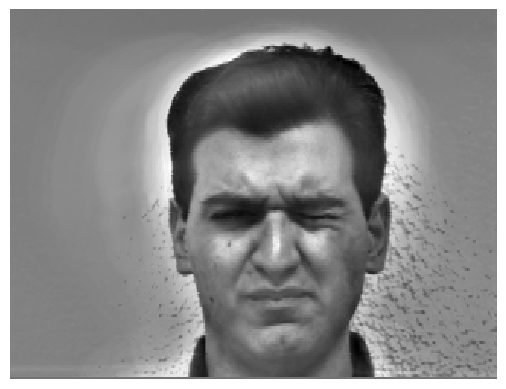

In [21]:
import matplotlib.pyplot as plt
from pathlib import Path

X_pca =  (U.dot(Z)).T
for i in range(N):
    Xhat[:, i] = X[:, i] + x_mean[:]
    
print(X_pca.shape)


# path to save reduced dim. images 
path_save = 'D:\\Teach_n_Train\\Machine Learning\\code\\yale\\yalefaces_data\\result_K69\\'

OUT_DIR = Path(path_save)
OUT_DIR.mkdir(parents=True, exist_ok=True)

for i in range(X_pca.shape[0]):
    plt.axis('off')
    f1 = plt.imshow(X_pca[i, :].reshape(h, w), interpolation='nearest')
    f1.axes.get_xaxis().set_visible(False)
    f1.axes.get_yaxis().set_visible(False)

    plt.gray()
    fn = path_save + 'eigenface' + str(i).zfill(2) + '.png'
    plt.savefig(fn, bbox_inches='tight', pad_inches=0)
#     plt.show()